
# Laboratorium 2: Baseline i kasyfikator



W poprzednim laboratorium zaczęliśmy od danych. Dzisiaj budujemy pierwszy pełny eksperyment z zakresu uczenia maszynowego.

Nasza ścieżka:

`dane → baseline → TF-IDF → klasyfikator → metryki → analiza błędów → decyzja`

Interesuje nas:

- jakość,
- stabilność,
- szybkość,
- koszt,
- interpretowalność,
- rodzaj popełnianych błędów.

> **Pytanie badawcze na dziś:** jak mocny jest prosty model tekstowy i kiedy naprawdę potrzebujemy transformera albo LLM-a?

## Po tych zajęciach student potrafi:

- zbudować klasyfikator;
- reprezentować tekst przez TF-IDF;
- wytrenować `LogisticRegression` i `LinearSVC`;
- poprawnie używać `accuracy`, `macro-F1`, `precision`, `recall`;
- analizować confusion matrix;
- porównywać modele eksperymentalnie;
- sprawdzać wpływ długości tekstu na wynik;
- analizować najbardziej pewne błędne predykcje;
- interpretować cechy modelu liniowego;
- przeprowadzić mini „NLP Arena”.

### Zasada na dziś

> **Nowy, większy model musi pokonać mocny baseline. Inaczej nie wiemy, czy naprawdę coś zyskaliśmy.**


## Dane

Laboratorium zakłada, że po wykonaniu laboratorium 1 mają Państwo:

```text
artifacts/polemo2_clean.parquet
artifacts/splits.json
```

Jeśli plików nie ma, proszę wrócić do Lab 1. Nie pobieramy danych ponownie, bo wtedy tracimy czyszczenie, manifest i sumy kontrolne.
Pracujemy na oryginalnym podziale zbioru.


## Setup

In [2]:
# !pip install pandas numpy matplotlib scikit-learn pyarrow joblib

In [3]:

from pathlib import Path
import json
import time
import os
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import ParameterGrid
import joblib
import hashlib

RANDOM_STATE = 42
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

pd.set_option("display.max_colwidth", 180)
pd.set_option("display.max_columns", 50)


In [4]:
def bootstrap_ci(y_true, y_pred, metric, n_boot=1000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    n = len(y_true)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        stats.append(metric(y_true[i], y_pred[i]))
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(metric(y_true, y_pred)), float(lo), float(hi)

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

In [5]:
DATA_PATH = ARTIFACTS / "polemo2_clean.parquet"
MANIFEST_PATH = ARTIFACTS / "splits.json"

# TODO: wczytać dane z Lab 1 i utworzyć train_df, val_df, test_df.
# Proszę sprawdzić:
#  - czy suma SHA-256 pliku parquet zgadza się z wartością w splits.json,
#  - czy etykiety to dokładnie: plus / minus / zero / amb,
#  - czy rozmiary splitów zgadzają się z split_sizes_clean z manifestu.
# Jeśli pliku nie ma, proszę wrócić do Lab 1 (nie pobieramy danych "po cichu").

df = pd.read_parquet(DATA_PATH)
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df   = df[df["split"] == "validation"].reset_index(drop=True)
test_df  = df[df["split"] == "test"].reset_index(drop=True)

In [6]:
parquet_sha = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert parquet_sha == manifest["parquet_sha256"], f"SHA-256 się nie zgadza: {parquet_sha}"

expected_labels = {"plus", "minus", "zero", "amb"}
actual_labels = set(df["target"].unique())
assert actual_labels == expected_labels, f"Błędne etykiety: {actual_labels}"

split_sizes = {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
assert split_sizes == manifest["split_sizes_clean"], f"Błędne rozmiary splitów: {split_sizes}"

> Dane wczytały się poprawnie i wszystkie checki przechodzą.


# Zadanie 1: Zamrożenie protokołu eksperymentalnego

Zanim wytrenują Państwo model, proszę zdefiniować zbiory:

- **train**: do uczenia,
- **validation**: do wyboru wariantu,
- **test**: testowany dopiero na końcu,
- główną metrykę,
- metryki pomocnicze.

### Dla tego laboratorium

Główna metryka: `macro-F1`

Dlaczego nie samo accuracy?

Bo `macro-F1` liczy F1 osobno dla każdej klasy, a potem uśrednia je z równą wagą. Słaba jakość na małej klasie nie „schowa się” za dużą klasą.




### Hipoteza badawcza

Przed uruchomieniem modeli proszę wpisać hipotezę:

> Który model wygra: prosty baseline, Logistic Regression czy Linear SVM? Dlaczego?

> Spodziewam się, że wygra któryś z modeli liniowych, ponieważ baseline przewiduje tylko klase większościową, więc słabo poradzi sobie na naszym zbiorze, natomiast Logistic Regression i Linear SVM poradzą sobie pewnie podobnie.

In [7]:
# MIEJSCE NA KOD

PRIMARY_METRIC = "macro_f1"
SECONDARY_METRICS = ["accuracy", "precision_macro", "recall_macro"]

print("train:", len(train_df), "| validation:", len(val_df), "| test:", len(test_df))

train_df["target"].value_counts(normalize=True).round(3)

train: 5783 | validation: 723 | test: 722


target
minus    0.379
plus     0.271
amb      0.182
zero     0.168
Name: proportion, dtype: float64


# Zadanie 2: Baseline większościowy

Najprostszy model klasyfikujący działa wg zasady: zawsze przewiduj najczęstszą klasę. Jeśli skomplikowany model ledwie pokonuje `DummyClassifier`, mamy problem.


In [8]:
# TODO: porównać dwa warianty DummyClassifier:
#   strategy="most_frequent"
#   strategy="stratified", random_state=RANDOM_STATE
# Raportować accuracy i macro-F1 na validation.

dummy_most_freq = DummyClassifier(strategy = "most_frequent")
dummy_stratified = DummyClassifier(strategy = "stratified", random_state=RANDOM_STATE)

results = []
for name, model in [("most_frequent", dummy_most_freq), ("stratified", dummy_stratified)]:
    model.fit(train_df["text"], train_df["target"])
    val_pred_base = model.predict(val_df["text"])
    results.append({
        "model": name,
        "accuracy": accuracy_score(val_df["target"], val_pred_base),
        "macro_f1": macro_f1(val_df["target"], val_pred_base),
    })

baseline_results = pd.DataFrame(results).round(2)
baseline_results

,model,accuracy,macro_f1
0,most_frequent,0.37,0.14
1,stratified,0.27,0.23


Proszę odpowiedzieć na pytania:

1. Dlaczego accuracy majority baseline może wyglądać „nieźle”?

> Accuracy na majority baseline może wyglądać nieźle, ponieważ zawsze przewiduje on klase większościową, jeśli model jest mocno niezbalansowany wynik ten może być dość wysoki, mimo to że model niczego się nie nauczył.

2. Dlaczego macro-F1 jest znacznie niższe?

> Dla pozostałych klas niż większościowa F1 wynosi 0, a macro-F1 uśrednia klasy z równą wagą. Model zostaje więc ukarany za ignorowanie pozostałych wartości.

3. Jaki wynik musi osiągnąć kolejny model, żeby w ogóle mówić o istotnym postąpieniu w analizie danych?

> Musi wyraźnie pokonać lepszy z baseline'ów w macro-F1, czyli w naszym przypadku około 0.23 ze stratified. Wyraźnie, czyli poza przedziałem ufności, jeśli przedziały modelu i baseline'u się nie nakładają, poprawa jest istotna.


# TF-IDF: zamieniamy tekst na dane liczbowe

Zamieńmy tekst na reprezentację liczbową. Najpierw budujemy macierz:

`dokument × cecha`

W klasycznym TF-IDF cechą może być słowo albo n-gram. Co jest bardziej znaczące dla tekstu?

Intuicja:

- słowo częste w konkretnym dokumencie jest ważne,
- słowo częste wszędzie wnosi mniej informacji o tekście i jego znaczeniu.

### Pierwszy wariant

- word n-grams: `(1, 2)`,
- `min_df=2`,
- maks. `50_000` cech,
- `sublinear_tf=True`.


In [9]:
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=2,
    max_features=50_000,
    sublinear_tf=True,
)

X_train = word_tfidf.fit_transform(train_df["text_norm"])


# Zadanie 3: Reprezentacja rzadka (Sparse Representation)

Proszę obliczyć liczbę wszystkich elementów macierzy, liczbę wartości niezerowych oraz gęstość macierzy. Następnie proszę wyjaśnić, dlaczego rzadka reprezentacja wektorowa dobrze sprawdza się w przypadku TF-IDF.


In [10]:
# TODO

total_cells = X_train.shape[0] * X_train.shape[1]
nonzero = X_train.nnz
density = nonzero / total_cells

print(f"Kształt macierzy: {X_train.shape}")
print(f"Wszystkie elementy: {total_cells:,}")
print(f"Wartości niezerowe: {nonzero:,}")
print(f"Gęstość: {density:.4%}")

Kształt macierzy: (5783, 50000)
Wszystkie elementy: 289,150,000
Wartości niezerowe: 648,306
Gęstość: 0.2242%


> Reprezentacja rzadka jest dużo lepsza w przypadku TF-IDF, ponieważ teksty zajmują bardzo dużo miejsca i spora część z danych jest pusta, dlatego trzymanie wyłącznie niepustych komórek znacznie oszczędza czas i miejsce.


# Regresja logistyczna (Logistic Regression)

To będzie nasz pierwszy prawdziwy klasyfikator. Model liniowy uczy wag przypisanych do cech tekstowych.
Dla klasy sentymentu może nauczyć się np., że:

- pewne słowa i frazy zwiększają prawdopodobieństwo `plus`,
- inne zwiększają prawdopodobieństwo `minus`.


In [11]:
# TODO: Pipeline(word_tfidf + LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

model_reg = Pipeline([
    ('tfidf', clone(word_tfidf)), 
    ('regression', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
model_reg.fit(train_df["text_norm"], train_df["target"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['amb','minus','plus','zero']"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",50000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'



# Zadanie 4: Klasyfikacja

Proszę zaprezentować pełny `classification_report`.

### Proszę odpowiedzieć na pytania:

1. Która klasa ma najwyższy recall?
2. Która ma najniższy?
3. Dla której klasy precision i recall najbardziej się różnią?
4. Która klasa jest dla modelu najtrudniejsza i dlaczego?
5. Co te liczby sugerują o danych?

In [12]:
# TODO: classification_report

val_pred_reg = model_reg.predict(val_df["text_norm"])

report_reg = pd.DataFrame(
    classification_report(val_df["target"], val_pred_reg, output_dict=True)
).T.loc[["plus", "minus", "zero", "amb"]]

report_reg["gap_prec_rec"] = (report_reg["precision"] - report_reg["recall"]).abs()

report_reg.round(3)

,precision,recall,f1-score,support,gap_prec_rec
plus,0.895,0.813,0.852,209.0,0.081
minus,0.781,0.948,0.857,271.0,0.167
zero,0.992,0.969,0.980,127.0,0.023
amb,0.600,0.414,0.490,116.0,0.186


1. Która klasa ma najwyższy recall?

> Najwyższy wynick recall ma klasa `zero`.

2. Która ma najniższy?

> Najniższy wynik recall ma klasa `amb`.

3. Dla której klasy precision i recall najbardziej się różnią?

> Największa różnica między precision a recall występuje dla klasy `amb` (~0.186).

4. Która klasa jest dla modelu najtrudniejsza i dlaczego?

> Najtrudniejszą klasą dla modelu jest `amb`, ponieważ ma on najniższy wynik precision, recall i f1-score. Teksty niejednoznaczne zawierają jednocześnie słownictwo pozytywne i negatywne, a model liniowy na TF-IDF sumuje wagi słów i nie rozumie, że sentyment jest mieszany.

5. Co te liczby sugerują o danych?

> Jakość mocno różni się między klasami. Model dobrze radzi sobie z wyraźnym sentymentem, a ma problem z tekstami niejednoznacznymi. Bardzo wysoki wynik zero może oznaczać, że ta klasa wyróżnia się cechami, przez które model nie do końca kieruje się sentymentem do oceny.


# Liniowe wekory nośne (Linear SVM)

Dla tekstu klasyczny Linear SVM jest bardzo mocnym baselinem - działa prosto i szybko, nie komplikuje nadmiernie agregowania informacji o tekście. Czy prosty model liniowy okaże się trudnym przeciwnikiem dla dużo większych modeli?


In [13]:
#TODO: LinearSVC()

model_svc = Pipeline([
    ('tfidf', clone(word_tfidf)), 
    ('svc', LinearSVC())
])

model_svc.fit(train_df["text_norm"], train_df["target"])
val_pred_svc = model_svc.predict(val_df["text_norm"])

report_svc = pd.DataFrame(
    classification_report(val_df["target"], val_pred_svc, output_dict=True)
).T.loc[["plus", "minus", "zero", "amb"]]

report_svc["gap_prec_rec"] = (report_svc["precision"] - report_svc["recall"]).abs()

report_svc.round(3)

,precision,recall,f1-score,support,gap_prec_rec
plus,0.863,0.813,0.837,209.0,0.050
minus,0.816,0.919,0.865,271.0,0.102
zero,0.969,0.992,0.981,127.0,0.023
amb,0.516,0.405,0.454,116.0,0.111


> Wyniki wyszły bardzo podobne do Logistic Regression, w niektórych miejsach są nieznacznie lepsze a w innych nieznacznie gorsze.


# Zadanie 5: Pierwszy leaderboard

Proszę zbudować tabelę:

| model | accuracy | macro-F1 | macro_f1_ci95 | macro-precision | macro-recall | train_s | infer_ms/doc |
|---|---:|---:|---:|---:|---:|---:|---:|

Modele:

- prosty baseline,
- TF-IDF + Logistic Regression,
- TF-IDF + Linear SVM.

Proszę posortować po macro-F1. Przedział ufności liczymy funkcją bootstrap_ci. Czas treningu mierzymy dla całego Pipeline (łącznie z TF-IDF), a infer_ms/doc jako medianę z 3 powtórzeń predict na validation.

### Ważne

To jest leaderboard na zbiorze walidacyjnym. Do pełnego porównania jeszcze dotrzemy.

In [14]:
models = {
    "Baseline (stratified)": dummy_stratified,
    "TF-IDF + Logistic Regression": model_reg,
    "TF-IDF + Linear SVM": model_svc,
}

rows = []
preds = {}
fitted = {}

for model_name, model in models.items():
    model_copy = clone(model)

    start = time.perf_counter()
    model_copy.fit(train_df["text_norm"], train_df["target"])
    train_s = time.perf_counter() - start

    times = []
    for _ in range(3):
        start = time.perf_counter()
        val_pred = model_copy.predict(val_df["text_norm"])
        times.append(time.perf_counter() - start)
    infer_ms = float(np.median(times)) / len(val_df) * 1000

    preds[model_name] = val_pred
    fitted[model_name] = model_copy

    y = val_df["target"]
    f1, lo, hi = bootstrap_ci(y, val_pred, macro_f1)

    rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y, val_pred),
        "macro-F1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]",
        "macro-precision": precision_score(y, val_pred, average="macro", zero_division=0),
        "macro-recall": recall_score(y, val_pred, average="macro", zero_division=0),
        "train_s": train_s,
        "infer_ms/doc": infer_ms,
    })

leaderboard_valid = (
    pd.DataFrame(rows)
    .sort_values("macro-F1", ascending=False)
    .reset_index(drop=True)
)
leaderboard_valid.round(4)

,model,accuracy,macro-F1,macro_f1_ci95,macro-precision,macro-recall,train_s,infer_ms/doc
0,TF-IDF + Logistic Regression,0.8271,0.7947,"[0.765, 0.824]",0.8170,0.7860,1.8332,0.0845
1,TF-IDF + Linear SVM,0.8188,0.7842,"[0.755, 0.812]",0.7913,0.7824,1.2798,0.0861
2,Baseline (stratified),0.2683,0.2310,"[0.204, 0.264]",0.2315,0.2314,0.0019,0.0004


> Logistic Regression i Linear SVM dają statystycznie zbliżone wyniki, bo ich przedziały ufności się pokrywają, a koszt treningu i inferencji jest podobny. Oba modele także wyraźnie pokonują baseline.


# Confusion Matrix. Jak model się myli?

Jedna liczba nie mówi nam, co dzieje się w modelu.

Macierz pomyłek odpowiada m.in. na pytania:

- czy `amb` jest mylone z `plus`?
- czy `zero` wpada w `minus`?
- czy błędy są symetryczne?


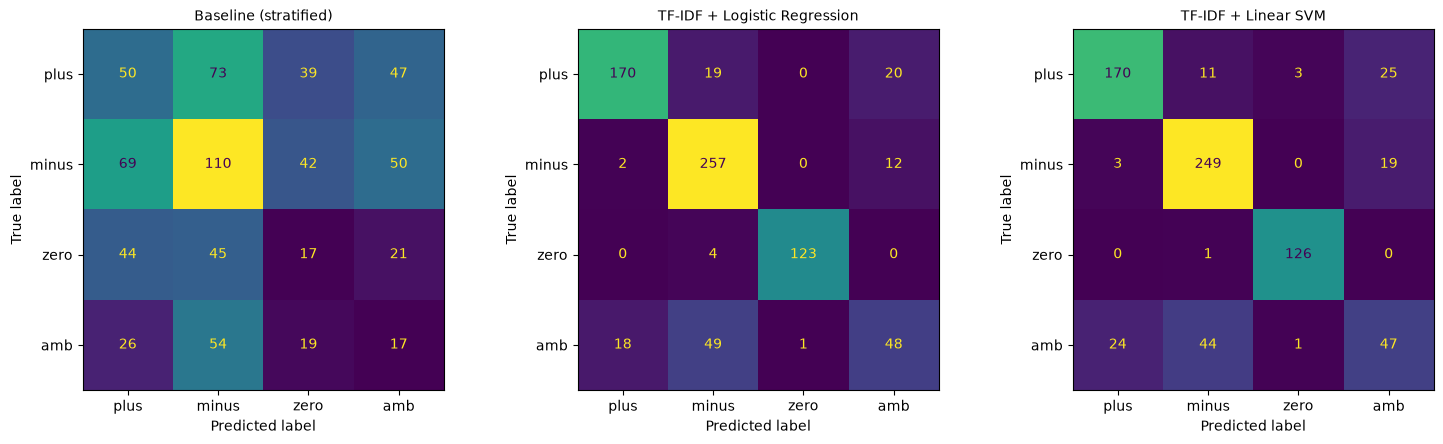

In [15]:
#TODO: ConfusionMatrix

CLASSES = ["plus", "minus", "zero", "amb"]

fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(
        val_df["target"], pred, labels=CLASSES, ax=ax, colorbar=False
    )
    ax.set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

Czy `amb` jest mylone z `plus`?

> Tak, wszystkim modelom zdarza się dość często pomylić klasę `amb` z `plus`.

Czy `zero` wpada w `minus`?

> W przypadku modelu Baseline zdarza się to dość często, jednak oba modele liniowe nie mają z tym problemu.

Czy błędy są symetryczne?

> Błędy nie są symetryczne, w niektórych przypadkach są dość podobne, ale znacznie różnią się od siebie.


# Zadanie 6: Interpretacja wartości

Proszę znaleźć i wskazać trzy największe wartości poza przekątną. Każdą taką wartość należy skomentować jednym zdaniem interpretacji.

Przykład formy (treść jest przykładowa, proszę opisać własne wyniki):

> Model często klasyfikuje `X` jako `Y`, co może sugerować, że ______.

> W interpretacji specjalnie pomijam Baseline, bo jego błędy są losowe i wynikają tylko z liczności klas.

> Największą pomyłką w przypadku obu modeli liniowych jest to, że klasyfikują `amb` jako `minus` (LR: 49 przykładów, SVM: 44 przykłady), co może sugerować, że w tekstach niejednoznacznych przeważa słownictwo negatywne albo że modelowi łatwiej przypisać etykietę minus niż rozpoznać mieszany sentyment.

> Regresja logistyczna myli `plus` prawie tak samo często z `amb` (20 przykładów) jak z `minus` (19 przykładów), co może sugerować, że recenzje pozytywne z krytycznymi fragmentami są dla niej niejednoznaczne i wpadają na dwie strony naraz.

> SVM częściej myli plus z `amb` (25 przykładów) i amb z plus (24 przykłady), co może sugerować, że granica między pozytywnym a niejednoznacznym sentymentem jest dla niego rozmyta w obu kierunkach. Tutaj jednak `plus` → `minus` zdarza się rzadziej niż przy RL: (11 przykładów).


# Word n-grams vs character n-grams

Polski jest językiem fleksyjnym. Jakie ma to znaczenie w przetwarzaniu języka?

Porównamy teraz dwie reprezentacje:

### A. słowa
```python
analyzer="word", ngram_range=(1, 2)
```

### B. znaki
```python
analyzer="char_wb", ngram_range=(3, 5)
```

Pozostałe parametry (`min_df=2`, `sublinear_tf=True`) muszą być takie same w obu wariantach, a `max_features` podany jawnie. Proszę raportować liczbę cech. Inaczej porównujemy nie reprezentację, tylko jej rozmiar (zasada „zmieniamy jeden element").

Character n-grams potrafią częściowo radzić sobie z:

- odmianą,
- literówkami,
- wariantami słowotwórczymi,
- nieformalną pisownią.

### Hipoteza

Która reprezentacja będzie lepsza na polskich recenzjach?

Proszę sformułować hipotezę przed wykonaniem eksperymentu.

> Uważam, że lepszą reprezentacją na polskich recenzjach będzie reprezentacja character n-grams, ponieważ w języku polskim słowa mają bardzo dużo odmian i repreznetacja character n-grams lepiej je wyłapie.

> Do porównania trzeba użyć tego samego modelu także zastosuję tutaj Linear SVC.

In [16]:
#TODO: word_ngrams vs. char_ngrams

word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2, max_features=50000, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=50000, sublinear_tf=True)

variants = {"word (1,2)": word_vec, "char_wb (3,5)": char_vec}

vectorizer_results = []

for name, vec in variants.items():
    pipe = Pipeline([("tfidf", clone(vec)), ("clf", LinearSVC(random_state=RANDOM_STATE))])
    pipe.fit(train_df["text_norm"], train_df["target"])
    pred = pipe.predict(val_df["text_norm"])
    n_features = len(pipe.named_steps["tfidf"].get_feature_names_out())
    
    accuracy = accuracy_score(val_df["target"], pred)
    f1, lo, hi = bootstrap_ci(val_df["target"], pred, macro_f1)
    
    vectorizer_results.append({
        "name": name,
        "n_features": n_features,
        "accuracy": accuracy,
        "macro-F1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]"
    })
        
pd.DataFrame(vectorizer_results)

,name,n_features,accuracy,macro-F1,macro_f1_ci95
0,"word (1,2)",50000,0.818811,0.784168,"[0.755, 0.812]"
1,"char_wb (3,5)",50000,0.828492,0.798431,"[0.769, 0.827]"


> Co ciekawe wyniki dla obu reprezentacji wyszły niemal identycznie, z minimalną przewagą reprezentacji char_ngrams. Dla dlatego eksperymentu nie można jednoznacznie stwierdzić, która z reprezentacji jest lepsza.


# Zadanie 7: Ablacja (Ablation study)

Proszę porównać co najmniej 4 warianty:

1. word unigram,
2. word `(1, 2)`,
3. char `(3, 5)`,
4. word `(1, 2)` z inną wartością `min_df` albo `max_features`.

Proszę użyć tego samego LinearSVC.

> UWAGA: zmieniamy jeden element pipeline'u i sprawdzamy, co rzeczywiście daje poprawę.

> Z racji, że warianty word (1, 2) oraz char (3, 5) sprawdzałem już wyżej, to dorzucę je do wyników zbiorczych a tutaj dołożę dwa inne do porównania.

In [17]:
#TODO: ablation_study

variants = {
    "word (1,1)": TfidfVectorizer(analyzer="word", ngram_range=(1, 1), min_df=2, max_features=50_000, sublinear_tf=True),
    "word (1,3)": TfidfVectorizer(analyzer="word", ngram_range=(1, 3), min_df=2, max_features=50_000, sublinear_tf=True),
    "char_wb (2,4)": TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2, max_features=50_000, sublinear_tf=True),
    "word (1,2), min_df=5": TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=5, max_features=50_000, sublinear_tf=True),
}

ablation_results = []

for name, vec in variants.items():
    pipe = Pipeline([
        ("tfidf", clone(vec)), 
        ("clf", LinearSVC(random_state=RANDOM_STATE))
    ])
    pipe.fit(train_df["text_norm"], train_df["target"])
    pred = pipe.predict(val_df["text_norm"])
    n_features = len(pipe.named_steps["tfidf"].get_feature_names_out())

    f1, lo, hi = bootstrap_ci(val_df["target"], pred, macro_f1)
    ablation_results.append({
        "variant": name,
        "n_features": n_features,
        "accuracy": accuracy_score(val_df["target"], pred),
        "macro-F1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]",
    })

for r in vectorizer_results:
    ablation_results.append({**{"variant": r["name"]}, **{k: v for k, v in r.items() if k != "name"}})

pd.DataFrame(ablation_results)

,variant,n_features,accuracy,macro-F1,macro_f1_ci95
0,"word (1,1)",29339,0.813278,0.781934,"[0.753, 0.811]"
1,"word (1,3)",50000,0.825726,0.795215,"[0.764, 0.823]"
2,"char_wb (2,4)",42002,0.829876,0.797916,"[0.769, 0.827]"
3,"word (1,2), min_df=5",23255,0.817427,0.786083,"[0.757, 0.813]"
4,"word (1,2)",50000,0.818811,0.784168,"[0.755, 0.812]"
5,"char_wb (3,5)",50000,0.828492,0.798431,"[0.769, 0.827]"


> Wszystkie warianty dają zbliżone macro-F1 (0,782–0,798), a ich przedziały ufności się pokrywają, więc żadna zmiana nie daje istotnej poprawy. Reprezentacje znakowe są nieznacznie lepsze.

> Przetestuje jeszcze Logistic Regression bo jestem ciekaw czy będzie się jakoś róznić.

In [59]:
all_variants = {**variants, "word (1,2)": word_vec, "char_wb (3,5)": char_vec}

lr_ablation_results = []

for name, vec in all_variants.items():
    pipe = Pipeline([
        ("tfidf", clone(vec)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ])
    pipe.fit(train_df["text_norm"], train_df["target"])
    pred = pipe.predict(val_df["text_norm"])

    f1, lo, hi = bootstrap_ci(val_df["target"], pred, macro_f1)
    lr_ablation_results.append({
        "variant": name,
        "accuracy": accuracy_score(val_df["target"], pred),
        "macro-F1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]",
    })

pd.DataFrame(lr_ablation_results)

,variant,accuracy,macro-F1,macro_f1_ci95
0,"word (1,1)",0.813278,0.779420,"[0.748, 0.807]"
1,"word (1,3)",0.828492,0.793145,"[0.764, 0.821]"
2,"char_wb (2,4)",0.825726,0.793436,"[0.764, 0.823]"
3,"word (1,2), min_df=5",0.829876,0.797956,"[0.768, 0.826]"
4,"word (1,2)",0.827109,0.794668,"[0.765, 0.824]"
5,"char_wb (3,5)",0.821577,0.786780,"[0.757, 0.815]"


> Wyniki podobne do SVC.


# Analiza błędów

To jest jedna z najważniejszych części laboratorium.

Żeby zrozumieć, jak i do jakich danych możemy nasz model zastosować, pytamy:

> „Jakie typy błędów popełnia model?”

Proszę zbudować DataFrame z:

- tekstem,
- gold labels,
- predykcją,
- informacją `correct`,
- długością tekstu.


> Tym razem wybrałem tu model Logistic Regression - ten trenowany w zadaniu 5.

In [18]:
#TODO: error_analysis

lr_name = "TF-IDF + Logistic Regression"
lr_model = fitted[lr_name]

error_analysis = pd.DataFrame({
    "text": val_df["text"],
    "gold": val_df["target"],
    "pred": preds[lr_name],
})
error_analysis["correct"] = error_analysis["gold"] == error_analysis["pred"]
error_analysis["n_words"] = val_df["text"].str.findall(r"\w+").str.len()
error_analysis["confidence"] = lr_model.predict_proba(val_df["text_norm"]).max(axis=1)

error_analysis.head()

,text,gold,pred,correct,n_words,confidence
0,"Pani Doktor bardzo miła , ale szkła dobrane mam źle - w gabinecie było ciemno ( nieodpowiednie oświetlenie gabinetu ) , a soczewki których używa okulista w gabinecie do badania...",minus,minus,True,64,0.560301
1,"Pani doktor jest rzeczowa , odpowiada na każde pytanie konkretnie , nie ogólnikami , co bardzo istotne . Spodobało mi się również podczas wizyty u Pani , jej szczera opinia i p...",plus,plus,True,93,0.456500
2,Powinno być zero albo nawet - 10 . Najgorszy lekarz u jakiego dotychczas była m . Poszła m z 3 miesięcznym niemowlakiem ze względu na kolki . Dostała m zestaw wszystkich możliw...,minus,minus,True,90,0.820233
3,Swoje osiągnięcie Mańka zaprezentował podczas trwającego od czwartku do piątku w Katowicach kongresu „ Investing in Medical Innovations ” . Opiera się ono na badaniach przeprow...,zero,zero,True,102,0.635867
4,""" To wymaga współpracy z instytutami badawczymi , wielkim przemysłem i wyszukiwania innowacyjnych pomysłów , które powstają w czasie badań naukowych , a potem wprowadzania ich ...",zero,zero,True,110,0.902704



# Zadanie 8: Zacne przypadki porażek

Proszę wylosować (`random_state=RANDOM_STATE`) 10 błędnych przykładów i dodatkowo wybrać 5 błędów o najwyższej pewności modelu (maksimum z predict_proba dla LogisticRegression). Każdemu proszę ręcznie przypisać kategorię błędu. Losowanie, a nie ręczny wybór, zapewnia reprezentatywność taksonomii.

Proponowana taksonomia:

- `AMBIGUOUS_GOLD`: etykieta sama jest dyskusyjna,
- `MIXED_SENTIMENT`: tekst zawiera pozytywne i negatywne fragmenty,
- `NEGATION`: problem z negacją,
- `IRONY_SARCASM`,
- `LONG_CONTEXT`,
- `VERY_SHORT`,
- `DOMAIN_TERM`,
- `SPELLING_NOISE`,
- `NON_REVIEW`: tekst wygląda na artykuł prasowy, a nie recenzję,
- `PRETOKENIZATION`: błąd związany ze spacjowaniem interpunkcji lub odciętymi końcówkami (`miała m`, `Był em`),
- `OTHER`.

Jeśli są potrzebne, proszę dodać wasne klasy.

### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|

In [29]:
errors = error_analysis[~error_analysis["correct"]]
print("Liczba błędów:", len(errors))

top_conf = errors.nlargest(5, "confidence")
random_err = errors.drop(top_conf.index).sample(10, random_state=RANDOM_STATE)

failures = pd.concat([top_conf.assign(source="top_conf"), random_err.assign(source="random")])

with pd.option_context("display.max_colwidth", None):
    display(failures[["source", "gold", "pred", "confidence", "n_words", "text"]])


Liczba błędów: 125


,source,gold,pred,confidence,n_words,text
688,top_conf,amb,minus,0.757640,183,"Wpadł em do Hotelu zaproszony przez kolegę organizującego koncert jednego z najbardziej uznanych gitarzystów na świecie . W związku z mym przyjazdem z UK zawitali śmy dopiero po koncercie - grubo po północy 31 . 03 . Panie z obsługi wpierw nie mogły znaleźdź rezerwacji dokonanej poprzez internet by później stwierdzić , że w sumie system nie przyjmuje mojej rezerwacji ( 30 - 31 / 03 ) tylko zaoferowały 31 - 1 . 04 . Ponieważ goście znajomego zostawali jeden dzień extra aby pozwiedzać , kolega zaproponował by m dołączył do nich i zgodził em się na pozostanie do 1 . 04 . Jakież było moje zdziwienie , kiedy po powrocie z Auschwitz drzwi pokoju zastał em zablokowane a pani w recepcji niemiłym tonem stwierdziła "" a to pan . Powinien pan rano oddać klucze . "" Na moje wytłumaczenia , mimo , że miałem świadka stwierdziła iż musiałem źle zrozumieć . Dopłacił em oczywiście late check out ale niesmak pozostał . Śniadanie w sumie oceniam rownież na 3 , masówka bez smaku . Raczej będę szukał innego miejsca następnym razem . Duża 3 z uwagi , że to RP . W Londynie nie wybaczył by m takiego podejścia ale zdaję sobie sprawę , że sprawy Rezerwacji internetowych czasem kuleją w tym kraju ."
247,top_conf,amb,plus,0.747864,46,"Z diety jestem bardzo zadowolona przepisy bardzo smaczne i szybkie w przygotowaniu . Duzym minusem jest czas oczekiwania na dietę ( ponad 2 tygodnie ) mimo częstego kontaktu ( sms , mail ) - co było dla mnie dużym zaskoczeniem ponieważ przy pierwszym spotkaniu Pani Martyna wydała się bardzo sympatyczna i kompetentna osoba ."
428,top_conf,amb,minus,0.737609,150,"Na początku miłe zaskoczenie , bo hotel zadzwonił po rezerwacji i poinformował nas że będą w tym czasie 2 wesela więc możemy oczywiście zrezygnować lub umieszczą nas jak najdalej od wesela . Ale po przyjeździe pokój okazał się być tuż nad wejściem do sali bankietowej , po interwencji w recepcji zmieniono nam pokój na oddalony od sali ale nadal z oknami na patio czyli tam gdzie goście wychodzili palić , parkowali auta i nad ranem urządzali typowo weselne awanturki . Jedzenie kiepskie , nie polecam , pokoje do remontu . . . i to gruntownego . Na drugim piętrze lekki zapaszek nikotyny , choć pokoje ponoć dla niepalących ( komentarz pani z recepcji odnośnie zapachu "" kiepa "" "" wie Pani jak jest , palić nie wolno , ale goście swoje . . . "" hmm ) zdecydowanie nie standard 3 gwiazdek , nawet nie 2 . Ogólnie , miejsce z którego można by wykrzesać fajną atmosferę , jednak zaniedbane i zakurzone . Sala bankietowa w historycznej części , kameralna i klimatyczna ( nie dziwne że chętnie wynajmowana na wesela ) ."
555,top_conf,amb,minus,0.728980,190,"Witam , wybrali śmy się na wyjazd całą rodziną z dwójką dzieci ( 6 + 2 lata ) - dojazd z Waszawy to koszmar , ale o to raczej nie można winić hotelu . Sam hotel nowy , przestronny , czysty , basen i część spa bardzo przyjemna , chociaż sala zabaw dziecięcych powinna być co najmniej raz dziennie sprzątana , a przy najmniej odkurzana ( podczas zabawy z córką znalazł em pokruszone szkło na dywanie ) . Natomiast to co zostało zaprezentowane w odniesieniu do kuchni hotelowej to jakiś koszmar . Nie należymy do wykwintnych koneserów żywieniowych , ale dania w tym hotelu do po prostu obrzydlistwo ! ! ! Rosół tak mocno z kostki , że nie daje sie jeść , kołduny w bulionie w ogóle chyba podane zepsute bo taki ocet , że nie dało rady nawet spróbować , podpłomyk z kindziukiem to gotowy spód od pizzy z serem i kindziukiem wrzucony do mikrofalówki - podany na zimno z nierozpuszczonym do końca serem . . . . dramat . Oczywiście ceny jak przystało na elegancki hotel po warszawsku , ale niestety nikomu nie przyszło do głowy żeby do rachunku nie doliczać dań , które zostały oddane bez zjedzenia . . . Overall nie polecam bo musieli śmy codziennie szukać msca na obiad co w tamtej okolicy nie jest ani łatwe ani przyjemne ."
194,top_conf,amb,plus,0.728149,69,"Powiem tak . każd

> Moje oceny:

In [ ]:
error_types = {
    688: "AMBIGUOUS_GOLD", 247: "MIXED_SENTIMENT", 428: "AMBIGUOUS_GOLD",
    555: "AMBIGUOUS_GOLD", 194: "MIXED_SENTIMENT", 321: "MIXED_SENTIMENT", 
    343: "AMBIGUOUS_GOLD", 48: "MIXED_SENTIMENT", 397: "MIXED_SENTIMENT", 
    189: "AMBIGUOUS_GOLD", 449: "LONG_CONTEXT", 494: "MIXED_SENTIMENT",
    76: "DOMAIN_TERM", 302: "NEGATION", 668: "SPELLING_NOISE",
}

failures["error_type"] = failures.index.map(error_types)
display(failures[["source", "gold", "pred", "confidence", "n_words", "error_type", "text"]])

,source,gold,pred,confidence,n_words,error_type,text
688,top_conf,amb,minus,0.757640,183,AMBIGUOUS_GOLD,Wpadł em do Hotelu zaproszony przez kolegę organizującego koncert jednego z najbardziej uznanych gitarzystów na świecie . W związku z mym przyjazdem z UK zawitali śmy dopiero p...
247,top_conf,amb,plus,0.747864,46,MIXED_SENTIMENT,Z diety jestem bardzo zadowolona przepisy bardzo smaczne i szybkie w przygotowaniu . Duzym minusem jest czas oczekiwania na dietę ( ponad 2 tygodnie ) mimo częstego kontaktu ( ...
428,top_conf,amb,minus,0.737609,150,AMBIGUOUS_GOLD,"Na początku miłe zaskoczenie , bo hotel zadzwonił po rezerwacji i poinformował nas że będą w tym czasie 2 wesela więc możemy oczywiście zrezygnować lub umieszczą nas jak najdal..."
555,top_conf,amb,minus,0.728980,190,AMBIGUOUS_GOLD,"Witam , wybrali śmy się na wyjazd całą rodziną z dwójką dzieci ( 6 + 2 lata ) - dojazd z Waszawy to koszmar , ale o to raczej nie można winić hotelu . Sam hotel nowy , przestro..."
194,top_conf,amb,plus,0.728149,69,MIXED_SENTIMENT,"Powiem tak . każdy lekarz jest dobry jak wszystko dobrze się kończy . Ja chodziła m do pana dr prywatnie , wizyty bardzo miłe , poświęcał dużo uwagi i czasu . Na oddziale bardz..."
321,random,amb,plus,0.712290,45,MIXED_SENTIMENT,"Pani doktor na wszystkie dolegliwości zapisuje od razu antybiotyk , na badania też nie lubi wysyłać . W związku z tym organizm osłabiony , choroba wciąż nawraca , a ja nie wiem..."
343,random,amb,minus,0.479449,57,AMBIGUOUS_GOLD,"Bywał em w hotelach Ibis już kila krotonie , porównując ten hotel do Hotelu Ibis Stare Miasto . Oceniam go negatywnie . Kabina prysznicowa mniejsza niż na Starym Mieście , TV t..."
48,random,amb,plus,0.381567,45,MIXED_SENTIMENT,"Wizyta neutralna . Lekarz wzbudza zaufanie , zobaczymy jak będzie przebiegało leczenie i interpretacja dalsza wyników badań . Ma dużo do powiedzenia , w sumie jest specjalista ..."
397,random,plus,amb,0.428690,178,MIXED_SENTIMENT,"Po pierwsze , jest to piękny duży hotel , zarówno od wewnątrz jak i na zewnątrz . Metro jest tuż obok , taksówki tuż za rogiem , a atrakcje w mieście są oddalone o zaledwie kil..."
189,random,amb,zero,0.384809,211,AMBIGUOUS_GOLD,"Mam nadzieję , że czas zrobił swoje ! Że przeczytane tutaj , negatywne opinie , nie potwierdzą się i po zabiegu - septoplastyce - będę mogła przyłączyć się do opinii "" najlepsz..."


### Wynik

| error_type | count | przykład | obserwacja |
|---|---:|---|---|
| MIXED_SENTIMENT | 6 | Pani doktor na wszystkie dolegliwości zapisuje od razu antybiotyk , na badania też nie lubi wysyłać . W związku z tym organizm osłabiony , choroba wciąż nawraca , a ja nie wiem co mi jest . Plusem jest to , że jest naprawdę bardzo miła i delikatna w kontaktach z pacjentem . | Opinia jest niejezdoznaczna, ale zawiera sporo słówch nacechowanych mocno pozytywnie (plusem, miła, delikatna). |
| AMBIGUOUS_GOLD | 5 | Wpadł em do Hotelu zaproszony przez kolegę organizującego koncert jednego z najbardziej uznanych gitarzystów na świecie . W związku z mym przyjazdem z UK zawitali śmy dopiero po koncercie - grubo po północy 31 . 03 . Panie z obsługi wpierw nie mogły znaleźdź rezerwacji dokonanej poprzez internet by później stwierdzić , że w sumie system nie przyjmuje mojej rezerwacji ( 30 - 31 / 03 ) tylko zaoferowały 31 - 1 . 04 . Ponieważ goście znajomego zostawali jeden dzień extra aby pozwiedzać , kolega zaproponował by m dołączył do nich i zgodził em się na pozostanie do 1 . 04 . Jakież było moje zdziwienie , kiedy po powrocie z Auschwitz drzwi pokoju zastał em zablokowane a pani w recepcji niemiłym tonem stwierdziła " a to pan . Powinien pan rano oddać klucze . " Na moje wytłumaczenia , mimo , że miałem świadka stwierdziła iż musiałem źle zrozumieć . Dopłacił em oczywiście late check out ale niesmak pozostał . Śniadanie w sumie oceniam rownież na 3 , masówka bez smaku . Raczej będę szukał innego miejsca następnym razem . Duża 3 z uwagi , że to RP . W Londynie nie wybaczył by m takiego podejścia ale zdaję sobie sprawę , że sprawy Rezerwacji internetowych czasem kuleją w tym kraju . | Jest to opinia jednoznacznie nacechowana negatywnie, więc nic dziwnego, że model zakwalifikował ją jako minus. Etykieta Gold jest tu mocno dyskusyjna. |
| LONG_CONTEXT | 1 | Hotel jest rewelacyjny , absolutnie nie ma się do czego przyczepić . Jedzenie pyszne ( 7dni + 3kg ) , duży wybór ryb , miesa , warzyw . W barze olbrzymi wybór alkoholi ( nawet oryginalne tj . Bacardi ) . Przy basenie automaty do własnej obsługi : cola i tego typu napoje , shake mleczne , maszynka do lodów włoskich ( mmm ) , maszyna z napojami mrożonymi , kawa , herbata , soki , zamrażalka z 6 smakami lodów . Obsługa przyjazna , służąca pomocą w każdym przypadku i o każdej porze . Widoki nieziemskie , morze gorące , do plaży faktycznie jest tylko przyjazny , krótki spacerek promenadą . Muzyka przy basenie od 10 : 30 - 24 : 00 . Animacje całkiem udane - zero ciągłego namawiania a i tak wszyscy się bawili . W hotelu przewaga grup z Polski , Niemiec i Anglii . Basen płytki , a woda okrutnie zimna , ale była dobrym ochłodzeniem . Pogoda we wrześniu - super . 30 stopni każdego dnia , a silne wiatry sprawiały , że tego nie czuć . Pokój duży , przestronny , wszystko tak jak należy . Byli śmy ze znajomymi i jesteśmy zachwyceni wszystkim co na nas czekało na miejscu , a będąc w Polsce tęsknimy za pysznym jedzonkiem i deserami . Wg naszej opinii hotel zasługuje na więcej niż 3 * , domyślała m się , że ich nie ma ze względu na : - brak udogodnień dla niepełnosprawnych , - brak windy , - brak możliwości przejścia gdziekolwiek bez konieczności chodzenia po schodach . Na basen schody , do pokoju schody , do restauracji , na plażę - schody ( ale to dobrze , może dlatego nie przytyła m jeszcze więcej : ) ) - do miasta / restauracji , klubów ( są 3 większe ) super blisko , ale dojazd do innych miejsc mimo autobusów niekiedy bywa utrudniony . Do palmy dojeżdża jeden autobus wyruszający z przystanku nieopodal hotelu tylko 2 razy dziennie , i jedzie aż 2 godziny , koszt takiej wyprawy to 18 , 10 E . Do bliżej położonych miejsc autobusy zdecydowanie częściej , jednak zabierają wiele osób dlatego nawet 10 km potrafi trwać 40 minut . Dobrze , że są klimatyzowane a w luźniejszych godzinach można usiąść : ) Jeśli ktoś jest zainteresowany wynajęciem samochodu to nie wygląda to tak źle choć warto uważnie patrzeć na umowy ( mówią , że nie ma kaucji , a potem jest doliczane po 20 E za opóźnienie czy jakieś różne rzeczy ) . Myśleli śmy o skuterze , ale nawet za niego było aż 200 E kaucji i 30 za wynajęcie . Poradzili śmy sobie bez tego ponieważ byli śmy nastawieni na wypoczynek więc podróż autobusem również traktowali śmy jako zwiedzenia okolicy i podziwianie widoków , a ponadto w barach nikt nie żałuje alkoholu więc ciężko było by wstać rano za kierownice . ABSOLUTNIE POLECAM ! | Opinia jest pozytywna, aczkolwiek strasznie długa, z racji tego zawiera dużo słów zarówno pozytywnych jak i negatywnych, stąd pewnie klasyfikacja jako `amb`. |
| DOMAIN_TERM | 1 | Uważam dr Sosnowskiego za lekarza wartego polecenia . Niestety , była m u niego tylko na trzech wizytach , ponieważ ciąża okazała się obumarła , ale zachował się tak jak powinien - natychmiastowe skierowanie do szpitala oraz słowa otuchy , które bardzo mnie podbudowały . Przy najbliższej ciąży na pewno się na niego zdecyduję . | Opinia zawiera dość specyficzne słownictwo (ciąża okazała się obumarła), oraz ma też trochę negacji. |
| NEGATION | 1 | Wizyta była miła , ale nie stać mnie na tą Klinikę . Szkoda bo Pani Doktor ma mikroskop , którego szukała m dwa lata by wyciągnąć ze starego zęba leczonego kanałowo urwany kawałek metalu . Człowieka na rencie nie stać na nic i tu nie ma winy Pani Doktor . Pozdrawiam serdecznie . | Mamy to zarówno negację jak i to, że w zasadzie tylko pierwsze zdanie mówi nam, że opinia jest pozytywna, reszta jest neutralna bądź negatywna. |
| SPELLING_NOISE | 1 | Hotel dla osob malo wymagajacych . Pokoje czyste , codzienne sprzatane . Sniadania malo urozmaicone , praktycznie codziennie to samo . Sala zabaw dla dzieci to tak naprawde kacik w sali klubowej , ktory w . weekendy nie dziala bo wtedy sa wesela i inne imprezy . Zabawki zdekompletowane , zepsute , kredki polamane . Co do SPA , to porażka . Za szlafrok do Spa nalezy placic ( ! ! ! ! ! ) gdzie w wiekszosci hotelach jest norma . Co do zabiegu mialam wykonywany UWAGA na kamiennym stole na ktory polozona zostala mata . . . . Poprosilam o zmiane lozka bo bylo mi po prostu niewygodnie . Musialam.tez sie dopraszac o bielizne jednorazowa , bo Pani mi zaproponowwlw aby m . podczas masazu zostala w swojej . . . Dodatkowo Pani kosmetyczka chora a hotel nie przewidzial zastepstwa , wiec w zwiazku z tym reszta zabiegow byla niemozliwa . Ponadto jacuzzi zepsute . Na plus mila obsluga na recepcji . | Opinia sama w sobie jest w zasadzie neutralna, ale braki w polskich znakach oraz dużo interpunkcji. |

> Generlanie bazując na samych błędach tu omówionych, model wydaje się podejmować sensowne decyzje, większość pomyłek wystąpiło przy klasach `amb` co nie jest niczym dziwnym bo czytając je samemu zastanawiałem się czy etykieta Gold jest prawidłowa. 

> Prawie każda z tych błędnie zakwalifikowanych opinii ma cechy które można by przypisać do różnych taksonomii, określenie konkretnego powodu dlaczego model się pomylił bazując tylko na czytaniu opinii jest niemożliwe.


# Czy długość tekstu zmienia jakość?

PProszę podzielić split walidacyjny na 4 koszyki długości według **kwartyli** `n_words` z Lab 1 (`pd.qcut(val_df["n_words"], 4, duplicates="drop")`, liczone regexem `\w+`, nie `split()`). Stałe progi (0–10, 11–30, ...) mogą dać puste koszyki, bo recenzje w tym zbiorze są długie.

Proszę policzyć accuracy i macro-F1 osobno dla każdego koszyka.

### Uwaga

Macro-F1 na bardzo małym segmencie może być niestabilne. Istotne jest zaraportowanie `n`.

In [ ]:
# TODO: przypisanie koszyków i tabela: koszyk | n | accuracy | macro-F1

error_analysis["length_bin"] = pd.qcut(error_analysis["n_words"], 4, duplicates="drop")

length_results = []
for bin_, g in error_analysis.groupby("length_bin", observed=True):
    length_results.append({
        "koszyk": str(bin_),
        "n": len(g),
        "accuracy": accuracy_score(g["gold"], g["pred"]),
        "macro-F1": f1_score(g["gold"], g["pred"], labels=CLASSES, average="macro", zero_division=0),
    })

length_df = pd.DataFrame(length_results)
display(length_df.round(3))

,koszyk,n,accuracy,macro-F1
0,"(27.999, 71.0]",183,0.787,0.744
1,"(71.0, 101.0]",180,0.806,0.764
2,"(101.0, 133.0]",181,0.901,0.853
3,"(133.0, 637.0]",179,0.816,0.769


In [37]:
pd.crosstab(error_analysis["length_bin"], error_analysis["gold"])

gold,amb,minus,plus,zero
length_bin,,,,
"(27.999, 71.0]",31,71,78,3
"(71.0, 101.0]",34,50,69,27
"(101.0, 133.0]",22,60,26,73
"(133.0, 637.0]",29,90,36,24


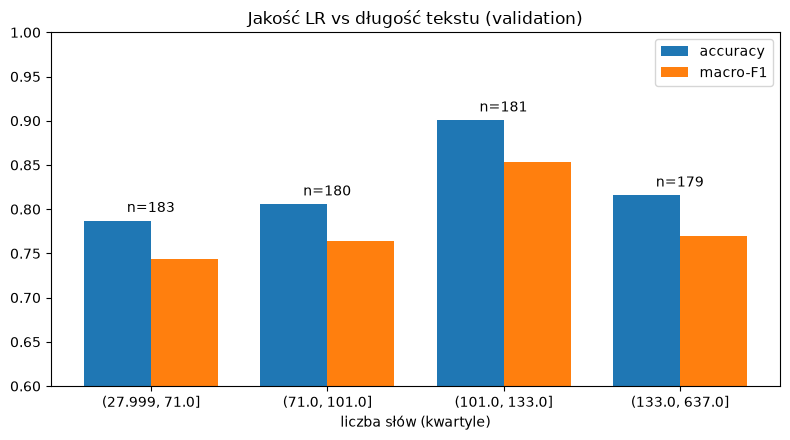

In [ ]:
x = np.arange(len(length_df))
w = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, length_df["accuracy"], w, label="accuracy")
ax.bar(x + w/2, length_df["macro-F1"], w, label="macro-F1")

for i, n in enumerate(length_df["n"]):
    ax.text(i, max(length_df.loc[i, ["accuracy", "macro-F1"]]) + 0.01, f"n={n}", ha="center")

ax.set_xticks(x, length_df["koszyk"])
ax.set_xlabel("liczba słów (kwartyle)")
ax.set_ylim(0.6, 1.0)
ax.set_title("Jakość LR vs długość tekstu (validation)")
ax.legend()
plt.tight_layout()
plt.show()

> Patrząc wyłącznie na wykres, wydaje się że długość tekstów może mieć znacznie, przedział (101, 133] wypada dużo lepiej niż pozostałe, jednak przeglądając rozkład klas w koszykach widać, że w tym przedziale większość tekstów jest klasy minus i zero, które model przewidywał niemal bezbłędnie, stąd różnica w wynikach metryk. Biorąc to pod uwagę model długość tekstu raczej nie wpływa na jakość w naszym przypadku.


# Czego właściwie nauczył się model?

Dla modelu liniowego możemy obejrzeć cechy o największych wagach.

To nie jest pełne wyjaśnienie modelu, ale bardzo użyteczne narzędzie diagnostyczne.

Dla każdej klasy proszę wypisać:

- 15 cech o najwyższej dodatniej wadze,
- 15 o najniższej.

Tym samym proszę sprawdzić, czy model uczy się sensownych sygnałów, czy przypadkowych artefaktów.


In [40]:
# TODO: dla LogisticRegression: pipeline.named_steps["tfidf"].get_feature_names_out() oraz clf.coef_ (kształt: klasy × cechy). Po 15 cech o najwyższej i najniższej wadze na klasę

feature_names = lr_model.named_steps["tfidf"].get_feature_names_out()
clf = lr_model.named_steps["regression"]

top_features = {}
for i, cls in enumerate(clf.classes_):
    order = np.argsort(clf.coef_[i])
    top_features[(cls, "top +")] = [f"{feature_names[j]} ({clf.coef_[i, j]:.2f})" for j in order[::-1][:15]]
    top_features[(cls, "top -")] = [f"{feature_names[j]} ({clf.coef_[i, j]:.2f})" for j in order[:15]]

pd.DataFrame(top_features)


amb                                    minus  \
               top +                top -               top +   
0         ale (3.16)      polecam (-1.98)  nie polecam (5.83)   
1          ok (2.46)  nie polecam (-1.70)          nie (5.30)   
2    niestety (2.17)     odradzam (-1.03)     odradzam (3.42)   
3      pokoje (1.84)       dzięki (-0.93)     niestety (2.80)   
4        brak (1.68)      lekarzy (-0.81)           po (2.37)   
5      jednak (1.62)       sposób (-0.79)         brak (2.29)   
6       minus (1.62)          lat (-0.79)          nic (2.10)   
7       dobre (1.60)         jego (-0.78)       brudne (1.93)   
8        dość (1.58)        nigdy (-0.78)          sie (1.92)   
9   śniadania (1.56)           dr (-0.77)        nawet (1.81)   
10      hotel (1.44)         proc (-0.77)       innego (1.62)   
11         za (1.42)        także (-0.76)      lekarza (1.55)   
12    ogólnie (1.41)        która (-0.74)        chyba (1.51)   
13      dobra (1.29)         roku (-0.73)           bo (1.47)   
14       plus (1.25)  jedyny plus (-0.71)       pokoju (1.46)   

                                    plus                                zero  \
              top -                top +                top -          top +   
0    zawsze (-1.99)       polecam (4.44)     niestety (-3.34)    proc (3.01)   
1    bardzo (-1.95)        bardzo (4.28)          nie (-3.26)    prof (2.94)   
2      jest (-1.59)        zawsze (2.20)  nie polecam (-2.99)  polsce (2.00)   
3    czysty (-1.56)       doktora (1.85)         brak (-2.46)     czy (1.91)   
4      prof (-1.51)       lekarzy (1.70)     odradzam (-1.61)     pap (1.86)   
5    czyste (-1.47)        jestem (1.68)           bo (-1.24)  będzie (1.81)   
6       dla (-1.45)          miła (1.67)          czy (-1.24)      są (1.76)   
7    dzięki (-1.43)        czyste (1.66)       jednak (-1.23)  hoteli (1.67)   
8     dobre (-1.41)        dzięki (1.64)           ok (-1.22)    roku (1.65)   
9   smaczne (-1.40)      dziękuję (1.62)           za (-1.20)   także (1.63)   
10  centrum (-1.29)    serdecznie (1.53)     nie jest (-1.13)    mogą (1.52)   
11     duży (-1.28)  bardzo dobre (1.52)         albo (-1.07)   które (1.50)   
12    także (-1.27)        doktor (1.51)        stare (-1.06)      np (1.49)   
13     proc (-1.27)      naprawdę (1.51)       brudne (-1.03)    oraz (1.46)   
14   czysto (-1.23)       smaczne (1.50)           zł (-1.02)     ich (1.44)   

                      
               top -  
0     bardzo (-2.86)  
1        nie (-2.78)  
2    polecam (-2.50)  
3       mnie (-2.47)  
4     doktor (-2.32)  
5       pani (-2.25)  
6    obsługa (-2.02)  
7         mi (-1.99)  
8         em (-1.92)  
9     pokoje (-1.85)  
10       ale (-1.77)  
11     hotel (-1.77)  
12        po (-1.65)  
13  niestety (-1.63)  
14       sie (-1.62)


# Zadanie 9: Ewaluacja cech

Proszę znaleźć:

1. trzy cechy, które wyglądają sensownie,
2. trzy cechy, które mogą być skrótem / artefaktem (podpowiedź: proszę przejrzeć tokeny krótkie i funkcyjne oraz pozostałości po pre-tokenizacji tekstów, np. `em`, `śmy`; domyślny tokenizer odrzuca tokeny jednoznakowe, więc `m` w `miała m` zniknie, a `em` w `Był em` zostanie),
3. jedną cechę, której obecność Cię zaskoczyła.

Następnie proszę odpowiedzieć:

> Czy wysoka waga cechy oznacza związek przyczynowy?

> 1. Trzy cechy, które wyglądają sensownie:
>    * nie polecam (`minus`) - typowo negatywna cecha
>    * polecam (`plus`) - typowo pozytywna cecha
>    * ale (`amb`) - cecha, która często pojawia się przy opiniach o mieszanym sentymencie
 
> 2. Trzy cechy, które mogą być skrótem / artefaktem:
>    * em (`zero`) - typowy artefakt po pre-toknenizacji
>    * proc (`zero`) - skrót od "procent", pewnie pojawiający się dość często w artykułach
>    * pep (`zero`) - także skrót, podobnbie jak wyżej

> 3. Jedną cechę, której obecność Cię zaskoczyła:
>    * doktora/lekarzy (`plus`) - ciekawe jest to, że model zakwalifikował te słowa jako pozytywne i to dość wysoko, być może opinie o lekarzach często były pozytywne

> Czy wysoka waga cechy oznacza związek przyczynowy? <br>
> Nie. Waga pokazuje tylko, że cecha często pojawia się razem z daną klasą w danych treningowych. Cecha "pap" nie sprawia, że tekst jest neutralny, tylko często może pojawiać się w artykułach prasowych. Na innych danych taka zależność może przestać działać.


# Prawdopodobieństwo predykcji i selektywna klasyfikacja

`LogisticRegression` zwraca `predict_proba`.

Możemy zbudować prostą zasadę:

> jeśli maksymalne prawdopodobieństwo < próg, model nie odpowiada.

To nazywamy m.in. abstention, reject option albo selektywną klasyfikacją.

W prawdziwym wdrożonym systemie czasem lepiej powiedzieć:

> „nie wiem / skieruj do człowieka”

niż wymusić odpowiedź.


In [43]:
#TODO: predict_proba

selective_df = error_analysis[["gold", "pred", "correct", "confidence"]].copy()

print(selective_df["confidence"].describe().round(3))
selective_df.groupby("correct")["confidence"].mean().round(3)

count    723.000
mean       0.633
std        0.163
min        0.275
25%        0.481
50%        0.633
75%        0.770
max        0.948
Name: confidence, dtype: float64


correct
False    0.483
True     0.664
Name: confidence, dtype: float64

> Widać, że pewność modelu faktycznie odróżnia trafienia od pomyłek.


# Zadanie 10: Pokrycie i jakość

Dla progów:

`0.40, 0.50, 0.60, 0.70, 0.80, 0.90`

proszę policzyć:

- `coverage`: na jakiej części danych model udziela odpowiedzi,
- accuracy na zaakceptowanych przykładach,
- macro-F1 na zaakceptowanych przykładach.

Uwaga: przy wysokich progach niektóre klasy mogą nie wystąpić wśród zaakceptowanych przykładów. Proszę liczyć `f1_score(..., labels=CLASSES, average="macro", zero_division=0)` i raportować `n` zaakceptowanych. Prawdopodobieństwa dostępne są tylko dla LogisticRegression (LinearSVC nie ma `predict_proba`).

Proszę narysować:

`coverage` vs `accuracy`

### Pytanie

Czy da się zwiększyć jakość systemu bez zmiany modelu? Jeśli tak, to jak?

In [52]:
# TODO: coverage vs accuracy

thresholds = [0.40, 0.50, 0.60, 0.70, 0.80, 0.90]
rows = []
for t in thresholds:
    accepted = selective_df[selective_df["confidence"] >= t]
    rows.append({
        "threshold": t,
        "n": len(accepted),
        "coverage": len(accepted) / len(selective_df),
        "accuracy": accuracy_score(accepted["gold"], accepted["pred"]),
        "macro-F1": f1_score(accepted["gold"], accepted["pred"], labels=CLASSES, average="macro", zero_division=0)
    })
coverage_df = pd.DataFrame(rows)
coverage_df.round(3)

,threshold,n,coverage,accuracy,macro-F1
0,0.4,667,0.923,0.855,0.810
1,0.5,522,0.722,0.929,0.852
2,0.6,402,0.556,0.950,0.806
3,0.7,278,0.385,0.971,0.740
4,0.8,144,0.199,1.000,0.750
5,0.9,23,0.032,1.000,0.750


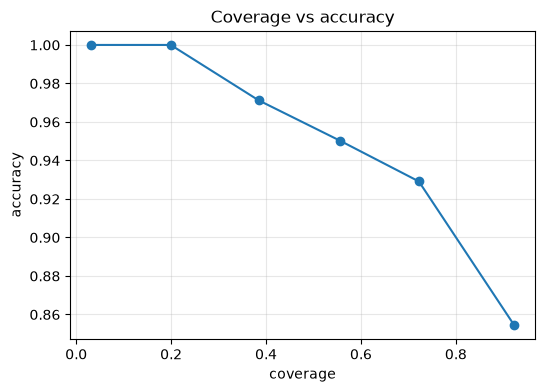

In [54]:
plt.figure(figsize=(6, 4))
plt.plot(coverage_df["coverage"], coverage_df["accuracy"], marker="o")
plt.xlabel("coverage")
plt.ylabel("accuracy")
plt.title("Coverage vs accuracy")
plt.grid(alpha=0.3)
plt.show()

In [24]:
# TODO: improvement_experiment


# Tuning hiperparametrów

Sprawdzimy jeden parametr Logistic Regression:

`C ∈ {0.1, 0.5, 1, 2, 5}`

Obliczeń dokonujemy na splicie walidacyjnym. To wystarczy, by przećwiczyć prawidłowy protokół:

`train → validation → wybór → test`


## Zadanie 11: Strojenie hiperparametru C

Proszę przeprowadzić strojenie hiperparametru C dla modelu regresji logistycznej.
- przetestować wartości C: 0.1, 0.5, 1.0, 2.0 i 5.0.
- dla każdej wartości wytrenować osobny model LogisticRegression na reprezentacji TF-IDF zbioru treningowego.
- wykonać predykcję dla zbioru walidacyjnego.
- obliczyć metryki jakości modelu, w szczególności macro F1.
- zapisać wyniki dla wszystkich wartości C w tabeli.
- posortować wyniki malejąco według macro F1.
- wybrać wartość C, dla której model uzyskał najlepszy wynik na zbiorze walidacyjnym.
Jeśli najlepsze C leży na brzegu siatki (5.0), proszę poszerzyć siatkę i powtórzyć.

Na końcu krótko odpowiedzieć: jak zmiana wartości C wpłynęła na jakość klasyfikacji i która wartość została wybrana?

In [56]:
# TODO: strojenie C na validation (nie na test!)

tfidf_c = clone(word_tfidf)
X_train_c = tfidf_c.fit_transform(train_df["text_norm"])
X_val_c = tfidf_c.transform(val_df["text_norm"])

C_GRID = [0.1, 0.5, 1.0, 2.0, 5.0]
c_results = []

for C in C_GRID:
    clf = LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE)
    clf.fit(X_train_c, train_df["target"])
    pred = clf.predict(X_val_c)

    f1, lo, hi = bootstrap_ci(val_df["target"], pred, macro_f1)
    c_results.append({
        "C": C,
        "accuracy": accuracy_score(val_df["target"], pred),
        "macro-F1": f1,
        "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]"
    })

pd.DataFrame(c_results).sort_values("macro-F1", ascending=False).reset_index(drop=True)

,C,accuracy,macro-F1,macro_f1_ci95
0,2.0,0.829876,0.799598,"[0.771, 0.827]"
1,5.0,0.821577,0.794892,"[0.766, 0.823]"
2,1.0,0.827109,0.794668,"[0.765, 0.824]"
3,0.5,0.818811,0.765456,"[0.735, 0.797]"
4,0.1,0.686030,0.573228,"[0.547, 0.596]"


> Najlepsze wartość C to 2.0, nie leży ona na brzegu siatki.

> Małe C oznacza silną regularyzację i prostszy model. Przy C = 0.1 model jest ograniczony i macro-F1 spada do 0.57. Od C = 1 wynik stabilizuje się na poziomie ok. 0.80, a większe C nic już nie poprawia. Wybrana została wartość C = 2.0, chociaż przewaga nad C = 1 i C = 5 jest niewielka.


# Zadanie 12: Finalista

Na podstawie splitu proszę wybrać jeden finalny pipeline.

Nie musi to być model z absolutnie najwyższym wynikiem, jeśli różnica jest minimalna, a koszt znacząco większy.

Proszę uzasadnić:

> **Wybrany model:** ...

> **Dlaczego:** ...

> **Najważniejszy trade-off:** ...



# Zadanie 13: Ostateczny test modelu

Kiedy mamy już wszystkie niezbędne informacje, wolno nam użyć test setu do finalnej oceny.

Proszę wybrać konfigurację na podstawie validation i:

1. połącz `train + validation`,
2. wytrenuj model od nowa,
3. oceń dokładnie raz na `test`.

Proszę nie poprawiać konfiguracji po zobaczeniu testu ;)


In [26]:
#TODO: TEST


# NLP Arena #1

Teraz model musi zostać oceniony jak system, a nie tylko liczba F1.

Dla finalistów raportujemy:

### Quality
- macro-F1,
- accuracy.

### Speed
- czas treningu,
- inference ms / dokument.

### Size
- rozmiar zapisanego pipeline'u.

### Robustness
- wynik na krótkich tekstach,
- wynik na długich tekstach.

### Interpretability
- czy możemy obejrzeć ważne cechy?

## Kategorie

**Best Quality**: najwyższe macro-F1  
**Speed Demon**: najniższe inference time  
**Tiny but Mighty**: najlepszy stosunek jakości do rozmiaru  
**Occam Award**: najprostszy system blisko najlepszego wyniku  
**Failure Analyst**: najlepsza analiza błędów


Proszę zapisać wytrenowany model do pliku i zmierzyć podstawowe parametry związane z jego wykorzystaniem.
- zapisać końcowy model do pliku w formacie joblib.
- obliczyć rozmiar zapisanego modelu w MB.
- wyświetlić czas treningu modelu w sekundach.
- obliczyć średni czas inferencji dla jednego dokumentu i podać go w milisekundach na dokument (ms/doc).
- zapisać otrzymane wartości i wykorzystać je później do porównania z innymi modelami.

Porównując modele, proszę zwrócić uwagę nie tylko na jakość klasyfikacji, ale również na ich rozmiar oraz koszt treningu i inferencji.

# Zadanie 14: Baseline Boss Fight

Zadanie związane z areną, skupiamy się w nim na następujących aspektach:

### A. Word + char features
Proszę połączyć reprezentację słowną i znakową przez `FeatureUnion`.

### B. Class weights
Sprawdzić `class_weight="balanced"`. Czy macro-F1 rośnie? Które klasy zyskują, a które tracą?

### C. Learning curve
Proszzę wytrenować ten sam model na:

- 10% train,
- 25%,
- 50%,
- 75%,
- 100%.

Proszę powtórzyć dla 3 różnych seedów losowania podzbiorów i raportować średnią ± odchylenie.

Proszę narysować:

`liczba przykładów → macro-F1`

Proszę odpowiedzieć: Czy bardziej opłaca się zmienić model, czy zdobyć więcej danych?

### D. Robustness test
Proszę zastosować zaburzenia do całego zbioru validation (n=723; 100 przykładów daje zbyt szeroki przedział ufności). Proszę wprowadzić kontrolowany szum:

- usunąć polskie znaki,
- dodać literówki,
- zmienić wielkość liter.

Proszę sprawdzić spadek wyniku word-TF-IDF i char-TF-IDF.

### E. Cost-aware model selection
Proszę zdefiniować własny score:

```text
utility = macro_f1 - λ * log10(model_size_mb + 1)
```
Proszę sprawdzić λ ∈ {0.01, 0.05, 0.1} i sprawdzić, czy najlepszy model nadal wygrywa.


# Zadanie 15: Karta modelu

Proszę utworzyć:

```text
artifacts/baseline_model_card.md
```

Minimalna zawartość:
- Jaki pipeline?
- Co przewiduje?
- Na czym został wytrenowany?
- Jakie splity i jaka główna metryka?
- Validation i final test.
- Czas treningu i inference.
- Co wynika z zaobserwowanych porażek?
- Czy próg confidence ma sens?
- Do czego model może być użyty? Do czego nie powinien być używany?



# Raport końcowy

Proszę podsumować pracę i określić:

1. **Najlepszy model:** ...
2. **Poprawa względem majority baseline:** ...
3. **Najtrudniejsza klasa:** ...
4. **Najważniejszy typ błędu:** ...
5. **Najważniejszy trade-off jakość/koszt:** ...
6. **Czy na tym etapie potrzebujemy większego modelu?** ...

Każde sformułowanie proszę uzasadnić.


# Warunki ukończenia laboratorium

Laboratorium jest skończone, jeśli zawiera:

- [ ] majority baseline (oba warianty `DummyClassifier`);
- [ ] TF-IDF i opis macierzy rzadkiej;
- [ ] Logistic Regression;
- [ ] Linear SVM;
- [ ] leaderboard na validation z przedziałami ufności;
- [ ] classification report;
- [ ] confusion matrix;
- [ ] ablację word vs char n-grams;
- [ ] Failure Gallery z ręczną taksonomią błędów;
- [ ] analizę jakości względem długości tekstu;
- [ ] porównanie wag modelu liniowego;
- [ ] coverage vs quality;
- [ ] strojenie C (tabela, wybór na validation);
- [ ] wybór finalisty bez używania test setu;
- [ ] ostateczny test: train + validation, dokładnie jeden raz na test;
- [ ] zapisany model `.joblib` i pomiary (rozmiar, czas treningu, ms/doc);
- [ ] NLP Arena #1;
- [ ] Baseline Boss Fight;
- [ ] `baseline_model_card.md`;
- [ ] wnioski końcowe.